# Discriminability gradients, schematic's estimator → `gradients_schematic.pdf`

A fork of [`gradients.ipynb`](gradients.ipynb) that adds the estimator from
[`../figure_3/efficient_coding_schematic/decoding_orientations.ipynb`](../figure_3/efficient_coding_schematic/decoding_orientations.ipynb)
as `MEASURE = 'linear_fisher'` (the default here): **kernel-smoothed means** and **linear
Fisher information** from recorded trials.

* **Smoothing.** A neuron's mean rate at a stimulus is a weighted average over *all* its 2-object
  trials, each weighted by $\exp(-d^2 / 2\sigma^2)$ with $d^2 = \Delta\theta_0^2 + \Delta\theta_1^2$
  under the closer object pairing (`KERNEL_SIGMA_DEG`).
* **Fisher.** At each plotted stimulus $s$ and along each of `N_DIRECTIONS` directions $u$, the
  bias-corrected $d'^2$ between $s \pm (\text{STEP}/2)\,u$ — $(\Delta\mu)^2/\sigma^2 - \sum_t c_t^2$,
  the correction accounting for trials shared by the two overlapping kernels — summed over units
  and divided by $\text{STEP}^2$. That is $u^\top J u$ in finite-difference form; fitting
  $a + b\cos2\varphi + c\sin2\varphi$ over the directions gives $J$, exactly as the
  `'decoding'` measure does from accuracies. No Poisson model, no classifier, and every unit
  enters every point.

The rest is `gradients.ipynb` unchanged:

How the result of `../figure_3/efficient_coding_schematic/` extends from one stimulus to all of them.

The schematic compares two directions at one stimulus (A, antipodal north/south): rotating the
pair, $(1, 1)$, and changing its separation, $(1, -1)$. Here every point of the
$(\theta_0, \theta_1)$ plane gets one segment per population. The segment's **angle** is the
direction in which that population discriminates a small change of stimulus **best**, and its
**length** is proportional to how well (d′ per radian along it).

Both come from a 2 × 2 matrix $J(s)$ per stimulus, with $u^\top J u$ the squared d′ of a small
displacement along $u$: the direction is $J$'s top eigenvector and the length the square root of
its top eigenvalue. `MEASURE` chooses where $J$ comes from:

* **`'fisher'`** — Poisson Fisher information, $J = \sum_i \nabla c_i\,\nabla c_i^\top / c_i$,
  from each neuron's smoothed rate surface;
* **`'decoding'`** — the schematic's linear decoder on recorded trials, telling apart two stimuli
  `DECODE_STEP_DEG` apart along `N_DIRECTIONS` directions through each point. Each accuracy becomes
  $d' = 2\Phi^{-1}(\text{acc})$ and $d'^2$ over the directions is fit by $a + b\cos2\varphi +
  c\sin2\varphi$, which is exactly the form $u^\top J u$ takes. Results are cached per point.

Rates are smoothed with `decoding.ipynb`'s eligibility rule: a trial counts for a stimulus when both
objects are within `SMOOTH_DEG` of it. The direction is an axis, so the segments have no heads.
Lengths share one scale across both populations, so blue and orange can be compared directly — but
only relative to each other. See [`gradients_lib.py`](gradients_lib.py) for what is and is not
controlled.

On this plot a rotation of the pair runs along the diagonal $(1, 1)$ and a change of
separation along the anti-diagonal $(1, -1)$. The empty band around $\theta_0 = \theta_1$ (and its
wrapped corners) is where no stimulus was ever shown: the two objects were never closer than
~80°.

In [1]:
import sys

import numpy as np
from matplotlib import pyplot as plt

sys.path.insert(0, '.')
import common
import gradients_lib as gl

common.set_style()

# ── CONFIG ───────────────────────────────────────────────────────────────────
# The populations: every neuron is assigned to whichever model (retinotopic or relational) fits
# it better, and each population is then the top K of its neurons by fit strength.
SUBJECTS = ('Perle', 'Elgar')
K = 20                   # neurons in EACH population
# True: rank each animal separately and take K / len(SUBJECTS) from each, so they contribute
# evenly. False: one ranking over both animals, top K outright (mostly Monkey P, whose fits run
# stronger).
RANK_WITHIN_ANIMAL = False
# Rotated copies of each neuron, tiling the circle: copy r is the neuron's whole tuning turned by
# r * 360 / NUM_REPLICAS degrees (both objects' angles in every trial rotated). 1 = each neuron
# once, as recorded. Any value works, exactly; nothing is interpolated.
NUM_REPLICAS = 1
MIN_SEP_DEG = 83.0       # grid points with the objects closer than this are left empty

# ── The measure ──────────────────────────────────────────────────────────────
# 'fisher': Poisson Fisher information from each neuron's smoothed rate surface — local, cheap.
# 'decoding': the efficient-coding schematic's read-out — a linear classifier on recorded trials,
#             telling apart two stimuli DECODE_STEP_DEG apart along N_DIRECTIONS directions
#             through each plotted point; the best direction is fit from the accuracies.
# 'linear_fisher': decoding_orientations.ipynb's estimator — bias-corrected d'^2 between
#             kernel-weighted means of recorded trials, s +/- LF_STEP_DEG/2 along N_DIRECTIONS
#             directions, summed over units; J is fit from d'^2 / step^2 as for 'decoding'.
MEASURE = 'linear_fisher'

# ── Linear Fisher (MEASURE = 'linear_fisher'), as in decoding_orientations.ipynb ──
KERNEL_SIGMA_DEG = 20.0  # Gaussian kernel width on the (theta_0, theta_1) distance
LF_STEP_DEG = 25.0       # distance between the two stimuli compared (its PERTURB_DEG)

# ── Smoothing (decoding.ipynb's REAL_TOL_DEG mechanism) ─────────────────────
# A trial counts for a stimulus when BOTH objects are within SMOOTH_DEG of the stimulus objects
# they match (whichever pairing is better). 'box' is exactly that rule: the rate is the plain
# mean over those trials, and for 'decoding' it is each class's eligibility window.
# 'gaussian' weights every trial by exp(-0.5 (d / SMOOTH_DEG)^2) on the same distance instead
# (Fisher only; decoding always uses the box window).
SMOOTH_KERNEL = 'gaussian'
SMOOTH_DEG = 20.0
N_GRID = 12               # the (theta_0, theta_1) grid: N_GRID bins per angle (8 -> 45° cells)
MIN_RATE = 0.5           # Hz; floors the Poisson denominator of the Fisher information
# How the Fisher measure gets each neuron's gradient (MEASURE = 'fisher' only):
# 'local_fit' — fit a polynomial of degree FIT_DEGREE to the trials in the window and read the
#               slope off it. Unbiased at the edge of the stimulus set (the 80° floor).
# 'mean'      — central differences of the window mean. Biased at that edge: a window half
#               outside it averages trials on one side only, which flattens the gradient ACROSS
#               the edge (the separation direction) and pulls every population toward rotation
#               within ~one window of the floor.
GRADIENT = 'mean'
FIT_DEGREE = 1           # 1 = plane; 2 = quadric (exact at the very edge when noise-free, but too
                         # noisy at real trial counts — lengths spread ~2x more)
# Subtract each fitted gradient's sampling covariance before summing. Fisher information sums
# SQUARED gradients, so noise in a gradient estimate inflates it — most where the window is
# thinnest, at the edge, and in the direction across it. Without this, local_fit trades the
# rotation bias for a separation bias.
DEBIAS = True

# ── Decoding (MEASURE = 'decoding'), as in decoding.ipynb ───────────────────
DECODE_STEP_DEG = 20.0   # distance between the two stimuli decoded (the schematic's is ~21°)
N_DIRECTIONS = 6         # directions through each point, evenly over [0°, 180°); at least 3
                         # (used by 'decoding' and 'linear_fisher')
DECODE_N_TRIALS = 200    # pseudo-trials per stimulus in the training half
DECODE_N_TEST = 100      # pseudo-trials per stimulus in the held-out half
DECODE_SPLITS = 5        # cross-validation folds, over recorded trials
DECODE_C = 1.0           # L2 strength of the logistic regression
DECODE_SEED = 0
MIN_UNITS = 5            # a point is left empty if fewer units per population have enough trials
N_JOBS = 6               # points decoded in parallel (never all cores)

# ── Figure ───────────────────────────────────────────────────────────────────
STEP = 1                 # a segment at every STEP-th grid point (1 = every one of the 8 x 8)
FIGSIZE = (3.4, 3.6)
MAX_LEN_DEG = None       # the longest segment's length, in degrees; None = 90% of the spacing
LINE_WIDTH = 1.6
LINE_ALPHA = 0.9
COLORS = {'retinotopic': 'tab:blue', 'relational': 'tab:orange'}
DRAW_ORDER = ('retinotopic', 'relational')     # the last is drawn on top
OUTPUT = 'gradients.pdf'

## 1. The populations and their discriminability fields

In [2]:
units = gl.population_units(SUBJECTS, k=K, rank_within_animal=RANK_WITHIN_ANIMAL)
trials = gl.load_trials(units)
mask = gl.sampled_mask(N_GRID, MIN_SEP_DEG)

if MEASURE == 'fisher':
    if GRADIENT == 'local_fit':
        fits = {side: gl.local_linear_tables(t, N_GRID, SMOOTH_DEG, SMOOTH_KERNEL, NUM_REPLICAS,
                                             degree=FIT_DEGREE)
                for side, t in trials.items()}
        J = {side: gl.fisher_from_gradients(r, d0, d1, cov if DEBIAS else None,
                                            min_rate=MIN_RATE)
             for side, (r, d0, d1, cov) in fits.items()}
    elif GRADIENT == 'mean':
        tables = {side: gl.smoothed_tables(t, N_GRID, SMOOTH_DEG, SMOOTH_KERNEL, NUM_REPLICAS)
                  for side, t in trials.items()}
        J = {side: gl.fisher_field(t, min_rate=MIN_RATE) for side, t in tables.items()}
    else:
        raise ValueError(f"GRADIENT must be 'local_fit' or 'mean' (got {GRADIENT!r})")
elif MEASURE == 'decoding':
    rotated = {side: gl.rotated_trials(t, NUM_REPLICAS) for side, t in trials.items()}
    J, info = gl.decode_field(rotated, gl.plotted_points(mask, STEP), step_deg=DECODE_STEP_DEG,
                              n_directions=N_DIRECTIONS, tol_deg=SMOOTH_DEG,
                              n_trials=DECODE_N_TRIALS, n_test=DECODE_N_TEST,
                              n_splits=DECODE_SPLITS, C=DECODE_C, seed=DECODE_SEED,
                              min_units=MIN_UNITS, n_jobs=N_JOBS)
    n = info['n_units'][np.isfinite(info['n_units'])]
    print(f'units per population entering each point: median {np.median(n):.0f}, '
          f'range {n.min():.0f}-{n.max():.0f} of {len(rotated["relational"])}; '
          f'{(n < MIN_UNITS).sum()} of {len(n)} points left empty')
elif MEASURE == 'linear_fisher':
    rotated = {side: gl.rotated_trials(t, NUM_REPLICAS) for side, t in trials.items()}
    J, info = gl.linear_fisher_field(rotated, gl.plotted_points(mask, STEP),
                                     step_deg=LF_STEP_DEG, n_directions=N_DIRECTIONS,
                                     sigma_deg=KERNEL_SIGMA_DEG)
    ne = info['n_eff_min'][np.isfinite(info['n_eff_min'])]
    print(f'{len(rotated["relational"])} units per population (with rotated copies); smallest '
          f'effective trial count of any unit at a point: median {np.median(ne):.1f}, '
          f'min {ne.min():.1f}')
else:
    raise ValueError(f"MEASURE must be 'fisher', 'decoding' or 'linear_fisher' "
                     f"(got {MEASURE!r})")

fields = {side: gl.top_direction(j) for side, j in J.items()}
display(gl.summary(fields, mask).round(3))

  retinotopic : 20 of 497 (fit strength 0.312–0.431, median 0.345)
  relational  : 20 of 842 (fit strength 0.374–0.612, median 0.413)


20 units per population (with rotated copies); smallest effective trial count of any unit at a point: median 31.6, min 13.4


,n_points,median_abs_cos_rotation,frac_closer_to_rotation,median_dprime_per_rad
population,,,,
retinotopic,84,0.606,0.452,4.209
relational,84,0.988,1.000,5.361


## 2. The figure

`median_abs_cos_rotation` above is $|\cos|$ between each population's best direction and the
rotation axis $(1,1)/\sqrt2$, over every sampled grid stimulus: 1 is pure rotation, 0 pure
separation change, 0.71 halfway.

saved gradients.pdf


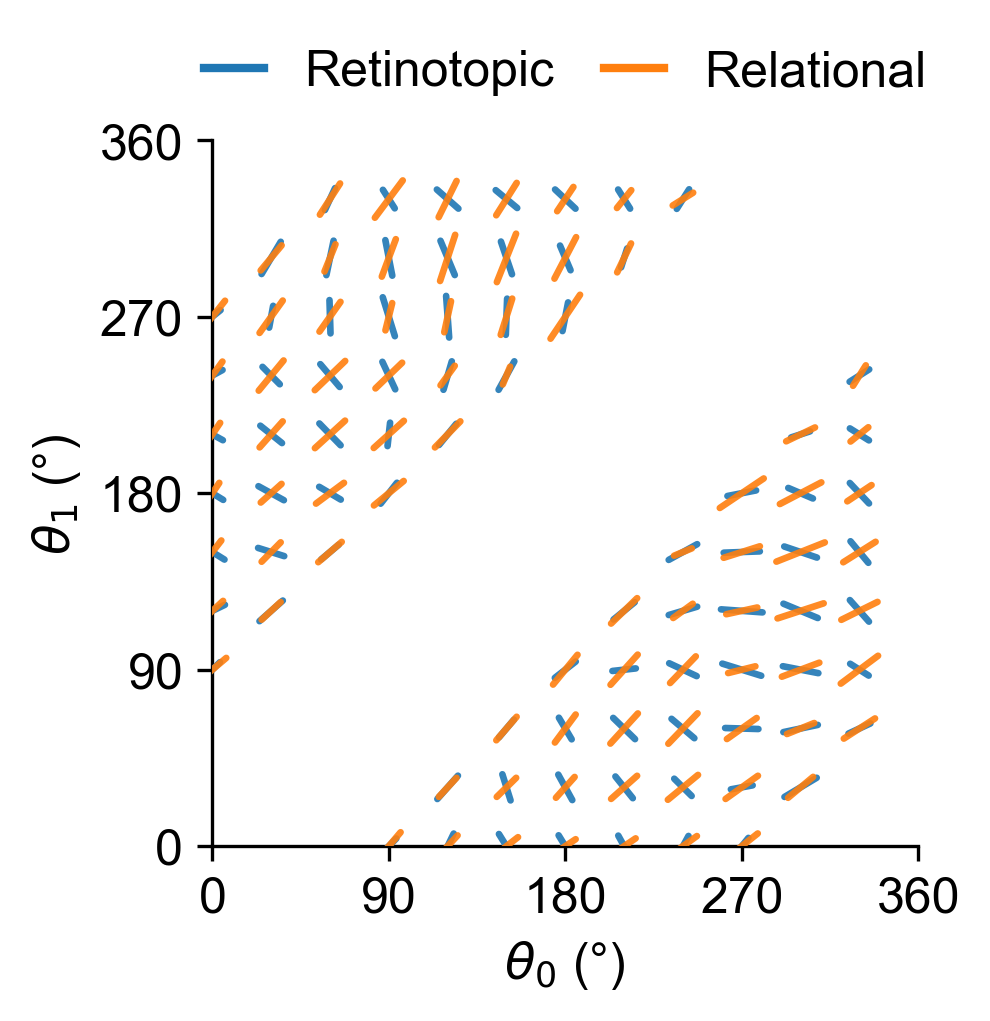

In [3]:
fig, ax = gl.plot_field(fields, mask, step=STEP, figsize=FIGSIZE, colors=COLORS,
                        max_len_deg=MAX_LEN_DEG, lw=LINE_WIDTH, alpha=LINE_ALPHA,
                        order=DRAW_ORDER)
common.save(fig, OUTPUT)
plt.show()
